# Chapter 14 — Example 14.1
## NSGA-II Basic: Pareto Front for Four-Bar Synthesis
Book: *Four-Bar Mechanisms: Design with GA and Neural Networks*

In [ ]:
from numpy import *
# Seed for reproducibility
random.seed(42)

## 1. Problem parameters

In [ ]:
from numpy import *
# Parameters of the multi-objective GA
POP   = 80      # population size
NGEN  = 40      # generations
PM    = 0.15    # prob.mutation
PC    = 0.85    # prob.crossing
D_REF = 100.0   # reference length (mm)
N_PTS = 36      # path points

## 2. Kinematics of the four-bar mechanism

In [ ]:
from numpy import *

def fourbar_positions(a, b, c, d=100.0, n=36):
    """Calculates positions of the coupler point (tip of link c)."""
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    pts = []
    for t2 in theta2:
        K1 = d/a; K2 = d/c
        K3 = (a**2 - b**2 + c**2 + d**2)/(2*a*c)
        A  = cos(t2) - K1 - K2*cos(t2) + K3
        B  = -2*sin(t2)
        C  = K1 - (K2+1)*cos(t2) + K3
        disc = B**2 - 4*A*C
        if disc < 0 or abs(A) < 1e-10:
            pts.append((nan, nan)); continue
        t4 = 2*arctan2(-B - sqrt(disc), 2*A)
        pts.append((c*cos(t4) + d, c*sin(t4)))
    pts = array(pts)
    mask = ~isnan(pts[:,0])
    return pts[mask] if mask.sum() > 3 else None

In [ ]:
from numpy import *
def hausdorff(X, Y):
    """Hausdorff distance between two sets of points."""
    if X is None or Y is None:
        return 1e6
    import builtins
    d = 0.0
    for x in X:
        d = builtins.max(d, builtins.min(sqrt(sum((x-y)**2)) for y in Y))
    for y in Y:
        d = builtins.max(d, builtins.min(sqrt(sum((x-y)**2)) for x in X))
    return d

In [ ]:
from numpy import *
def mu_deficit(a, b, c, d=100.0, mu_min=40.0, n=36):
    """f2: transmission angle deficit (degrees)."""
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    deficit = 0.0
    for t2 in theta2:
        num = b**2 + c**2 - (d - a*cos(t2))**2 - (a*sin(t2))**2
        den = 2*b*c
        if abs(den) < 1e-10: continue
        cos_mu = clip(num/den, -1, 1)
        mu = degrees(arccos(cos_mu))
        mu = mu if mu <= 90 else 180 - mu
        deficit = maximum(deficit, maximum(0, mu_min - mu))
    return deficit

## 3. Reference trajectory and Grashof

In [ ]:
from numpy import *
# Reference circular path (radius 30 mm, centered at (130, 0))
_n_pts = 36
theta_ref = linspace(0, 2*pi, _n_pts, endpoint=False)
TRAJ_REF  = column_stack([130 + 30*cos(theta_ref), 30*sin(theta_ref)])

def grashof_ok(a, b, c, d=100.0):
    L = sorted([a,b,c,d])
    return L[0] + L[3] <= L[1] + L[2]

## 4. NSGA-II — selection, crossover and mutation

In [ ]:
from numpy import *
def dominates(u, v):
    return all(u <= v) and any(u < v)

def non_dominated_sort(pop_f):
    N = len(pop_f)
    fronts = [[]]
    dom_count = zeros(N, int)
    dom_by    = [[] for _ in range(N)]
    for i in range(N):
        for j in range(N):
            if i == j: continue
            if dominates(pop_f[i], pop_f[j]):
                dom_by[i].append(j)
            elif dominates(pop_f[j], pop_f[i]):
                dom_count[i] += 1
        if dom_count[i] == 0:
            fronts[0].append(i)
    k = 0
    while fronts[k]:
        nxt = []
        for i in fronts[k]:
            for j in dom_by[i]:
                dom_count[j] -= 1
                if dom_count[j] == 0: nxt.append(j)
        fronts.append(nxt); k += 1
    return [f for f in fronts if f]

def crowding_distance(pop_f, front):
    n, m = len(front), pop_f.shape[1]
    dist = zeros(n)
    for k in range(m):
        order = argsort(pop_f[front, k])
        dist[order[0]] = dist[order[-1]] = 1e9
        frange = pop_f[front[order[-1]], k] - pop_f[front[order[0]], k]
        if frange == 0: continue
        for i in range(1, n-1):
            dist[order[i]] += (pop_f[front[order[i+1]], k] - pop_f[front[order[i-1]], k]) / frange
    return dist

In [ ]:
from numpy import *
def sbx_crossover(p1, p2, eta=15):
    child = zeros(3)
    for i in range(3):
        u = random.rand()
        beta = (2*u)**(1/(eta+1)) if u <= 0.5 else (1/(2*(1-u)))**(1/(eta+1))
        child[i] = clip(0.5*((1+beta)*p1[i]+(1-beta)*p2[i]), 20, 90)
    return child

def poly_mutation(x, eta=20):
    child = x.copy()
    for i in range(len(child)):
        if random.rand() < PM:
            u = random.rand()
            delta = (2*u)**(1/(eta+1))-1 if u<0.5 else 1-(2*(1-u))**(1/(eta+1))
            child[i] = clip(child[i] + delta*70, 20, 90)
    return child

## 5. NSGA-II Execution

In [ ]:
from numpy import *

# Backup parameters if the previous cell was not executed
POP = 80
PM = 0.15

def grashof_ok(a, b, c, d=100.0):
    L = sorted([a, b, c, d])
    return L[0] + L[3] <= L[1] + L[2]

def fourbar_positions(a, b, c, d=100.0, n=36):
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    pts = []
    for t2 in theta2:
        K1 = d/a; K2 = d/c
        K3 = (a**2 - b**2 + c**2 + d**2)/(2*a*c)
        A  = cos(t2) - K1 - K2*cos(t2) + K3
        B  = -2*sin(t2)
        C  = K1 - (K2+1)*cos(t2) + K3
        disc = B**2 - 4*A*C
        if disc < 0 or abs(A) < 1e-10:
            pts.append((nan, nan)); continue
        t4 = 2*arctan2(-B - sqrt(disc), 2*A)
        pts.append((c*cos(t4) + d, c*sin(t4)))
    pts = array(pts)
    mask = ~isnan(pts[:,0])
    return pts[mask] if mask.sum() > 3 else None

# Initialize population with valid Grashof individuals
pop = []
attempts = 0
while len(pop) < POP and attempts < 50000:
    abc = random.uniform(20, 90, 3)
    a, b, c = abc
    if grashof_ok(a, b, c) and fourbar_positions(a, b, c) is not None:
        pop.append(abc)
    attempts += 1
pop = array(pop)
print(f'Initial population: {len(pop)} valid Grashof individuals')

Initial population: 80 valid Grashof individuals


In [ ]:
from numpy import *

# Backup parameters if the previous cell was not executed
POP = 80
NGEN = 40
PM = 0.15

# Reference trajectory
_n_pts = 36
theta_ref = linspace(0, 2*pi, _n_pts, endpoint=False)
TRAJ_REF  = column_stack([130 + 30*cos(theta_ref), 30*sin(theta_ref)])

def dominates(u, v):
    return all(u <= v) and any(u < v)

def non_dominated_sort(pop_f):
    N = len(pop_f)
    fronts = [[]]
    dom_count = zeros(N, int)
    dom_by    = [[] for _ in range(N)]
    for i in range(N):
        for j in range(N):
            if i == j: continue
            if dominates(pop_f[i], pop_f[j]):
                dom_by[i].append(j)
            elif dominates(pop_f[j], pop_f[i]):
                dom_count[i] += 1
        if dom_count[i] == 0:
            fronts[0].append(i)
    k = 0
    while fronts[k]:
        nxt = []
        for i in fronts[k]:
            for j in dom_by[i]:
                dom_count[j] -= 1
                if dom_count[j] == 0: nxt.append(j)
        fronts.append(nxt); k += 1
    return [f for f in fronts if f]

def crowding_distance(pop_f, front):
    n, m = len(front), pop_f.shape[1]
    dist = zeros(n)
    for k in range(m):
        order = argsort(pop_f[front, k])
        dist[order[0]] = dist[order[-1]] = 1e9
        frange = pop_f[front[order[-1]], k] - pop_f[front[order[0]], k]
        if frange == 0: continue
        for i in range(1, n-1):
            dist[order[i]] += (pop_f[front[order[i+1]], k] - pop_f[front[order[i-1]], k]) / frange
    return dist

def sbx_crossover(p1, p2, eta=15):
    child = zeros(3)
    for i in range(3):
        u = random.rand()
        beta = (2*u)**(1/(eta+1)) if u <= 0.5 else (1/(2*(1-u)))**(1/(eta+1))
        child[i] = clip(0.5*((1+beta)*p1[i]+(1-beta)*p2[i]), 20, 90)
    return child

def poly_mutation(x, eta=20):
    child = x.copy()
    for i in range(len(child)):
        if random.rand() < PM:
            u = random.rand()
            delta = (2*u)**(1/(eta+1))-1 if u<0.5 else 1-(2*(1-u))**(1/(eta+1))
            child[i] = clip(child[i] + delta*70, 20, 90)
    return child

def hausdorff(X, Y):
    if X is None or Y is None:
        return 1e6
    import builtins
    d = 0.0
    for x in X:
        d = builtins.max(d, builtins.min([sqrt(sum((x-y)**2)) for y in Y]))
    for y in Y:
        d = builtins.max(d, builtins.min([sqrt(sum((x-y)**2)) for x in X]))
    return d

def mu_deficit(a, b, c, d=100.0, mu_min=40.0, n=36):
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    deficit = 0.0
    for t2 in theta2:
        num = b**2 + c**2 - (d - a*cos(t2))**2 - (a*sin(t2))**2
        den = 2*b*c
        if abs(den) < 1e-10: continue
        cos_mu = clip(num/den, -1, 1)
        mu = degrees(arccos(cos_mu))
        mu = mu if mu <= 90 else 180 - mu
        deficit = maximum(deficit, maximum(0, mu_min - mu))
    return deficit

def evaluate(ind):
    a,b,c = ind
    pts = fourbar_positions(a,b,c)
    f1 = hausdorff(pts, TRAJ_REF) if pts is not None else 1e6
    f2 = mu_deficit(a,b,c)
    return array([f1, f2])

pop_f = array([evaluate(ind) for ind in pop])

for gen in range(NGEN):
    # Generate offspring
    offspring = []
    while len(offspring) < POP:
        idx = random.permutation(len(pop))[:4]
        p1 = pop[idx[0]] if pop_f[idx[0],0]<pop_f[idx[1],0] else pop[idx[1]]
        p2 = pop[idx[2]] if pop_f[idx[2],0]<pop_f[idx[3],0] else pop[idx[3]]
        child = poly_mutation(sbx_crossover(p1, p2))
        a,b,c = child
        if grashof_ok(a,b,c):
            offspring.append(child)
    offspring   = array(offspring)
    offspring_f = array([evaluate(ind) for ind in offspring])
    # Combine and select by Pareto fronts
    combined   = vstack([pop, offspring])
    combined_f = vstack([pop_f, offspring_f])
    fronts = non_dominated_sort(combined_f)
    new_pop, new_f = [], []
    for front in fronts:
        if len(new_pop) + len(front) <= POP:
            for i in front:
                new_pop.append(combined[i])
                new_f.append(combined_f[i])
        else:
            cd = crowding_distance(combined_f, front)
            order = argsort(-cd)[:POP-len(new_pop)]
            for i in order:
                new_pop.append(combined[front[i]])
                new_f.append(combined_f[front[i]])
            break
    pop   = array(new_pop)
    pop_f = array(new_f)
    if (gen+1) % 10 == 0:
        print(f'Generation {gen+1:2d} completed.')

pareto_idx = non_dominated_sort(pop_f)[0]
pareto_f   = pop_f[pareto_idx]
pareto_x   = pop[pareto_idx]
print(f'Solutions in Pareto front: {len(pareto_idx)}')

Generation 10 completed.
Generation 20 completed.
Generation 30 completed.
Generation 40 completed.
Solutions in Pareto front: 80


In [ ]:
from numpy import *

# Ensure Pareto front extraction before reporting
pareto_idx = non_dominated_sort(pop_f)[0]
pareto_f   = pop_f[pareto_idx]
pareto_x   = pop[pareto_idx]

# Better in every objective
i1 = argmin(pareto_f[:,0])
i2 = argmin(pareto_f[:,1])

print('Best trajectory (minimum f1):')
print(f'  a={pareto_x[i1,0]:.1f} mm  b={pareto_x[i1,1]:.1f} mm  c={pareto_x[i1,2]:.1f} mm')
print(f'  f1 = {pareto_f[i1,0]:.2f} mm  |  f2 = {pareto_f[i1,1]:.2f}°')
print('Best transmission (minimum f2):')
print(f'  a={pareto_x[i2,0]:.1f} mm  b={pareto_x[i2,1]:.1f} mm  c={pareto_x[i2,2]:.1f} mm')
print(f'  f1 = {pareto_f[i2,0]:.2f} mm  |  f2 = {pareto_f[i2,1]:.2f}°')

Best trajectory (minimum f1):
  a=79.4 mm  b=61.7 mm  c=29.9 mm
  f1 = 30.07 mm  |  f2 = 40.00°
Best transmission (minimum f2):
  a=21.6 mm  b=90.0 mm  c=38.4 mm
  f1 = 75.55 mm  |  f2 = 0.00°


## 6. Visualization of the Pareto front

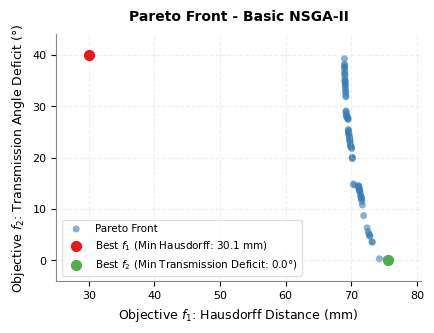

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Automated File Name System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex14_1_nsga2_basic"
except Exception:
    notebook_name = "ex14_1_nsga2_basic"

# 2. Springer Global Quality and Vector Font Configuration
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 8

# 3. Data Extraction and Optimization
# Extract Pareto front using already calculated pop_f from the kernel
pareto_idx = non_dominated_sort_visual(pop_f)[0]
pareto_f   = pop_f[pareto_idx]
pareto_x   = pop[pareto_idx]

i1 = np.argmin(pareto_f[:, 0])
i2 = np.argmin(pareto_f[:, 1])

# 4. Figure Construction
fig, ax = plt.subplots(figsize=(4.7, 3.2))

# Scatter plotting
ax.scatter(pareto_f[:, 0], pareto_f[:, 1], c='#377eb8', s=25, alpha=0.6, edgecolors='none', label='Pareto Front')
ax.scatter(pareto_f[i1, 0], pareto_f[i1, 1], c='#e41a1c', s=50, zorder=5, label=f'Best $f_1$ (Min Hausdorff: {pareto_f[i1, 0]:.1f} mm)')
ax.scatter(pareto_f[i2, 0], pareto_f[i2, 1], c='#4daf4a', s=50, zorder=5, label=f'Best $f_2$ (Min Transmission Deficit: {pareto_f[i2, 1]:.1f}°)')

# Labels and typography
ax.set_xlabel('Objective $f_1$: Hausdorff Distance (mm)', fontsize=9)
ax.set_ylabel('Objective $f_2$: Transmission Angle Deficit (°)', fontsize=9)
ax.set_title('Pareto Front - Basic NSGA-II', fontsize=10, fontweight='bold', pad=10)

# Formatting axes & grid
ax.grid(True, linestyle='--', alpha=0.3, color='#cccccc')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#888888')
ax.spines['bottom'].set_color('#888888')

# Prevent clipping and overlapping by adding margins
ax.set_xlim(np.min(pareto_f[:, 0]) - 5, np.max(pareto_f[:, 0]) + 5)
ax.set_ylim(np.min(pareto_f[:, 1]) - 4, np.max(pareto_f[:, 1]) + 4)

# Legend configuration
ax.legend(loc='lower left', frameon=True, framealpha=0.9, fontsize=7.5, facecolor='white', edgecolor='#dddddd')

# 5. Double Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()